# Regression Project

The time is now! It's up to you to help a poor waiter maximising his/her's tip in your first project. You will use the data collected by a waiter about each tip received over a period of a few months working in one restaurant. In total, he/she recorded 244 tips.

## Part 0 - Importing the Dataset

In [8]:
# RUN THIS CELL!

# Non-sklearn packages
import numpy as np
import pandas as pd
from seaborn import load_dataset

# Import the tips dataset
tips = load_dataset("tips")

## Part 1 - Explore the Dataset

In this part you should explore the dataset to understand it better. Maybe a simple place to start is with the Pandas' `.head()` command? Other commands that you can try is:
 - `.info()` - Check for missing values?
 - `.describe()` - Find means, medians, etc.
 - Let's also do some plotting. For example, does it seems like females tip more than males? Give a plot that shows whether or not this is the case. 
 - Also try to plot a scatter plot of the `total_bill` column and the `tip` column. Does it seem to be a strong relation between these columns?

In [9]:
# Check out the five first rows in the tips dataset
tips.head(10)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
7,26.88,3.12,Male,No,Sun,Dinner,4
8,15.04,1.96,Male,No,Sun,Dinner,2
9,14.78,3.23,Male,No,Sun,Dinner,2


In [10]:
# Looking at summery statistics
tips.info()


<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [11]:
# Check that there are no missing values
tips.describe()


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [12]:
tips.corr(numeric_only=True)

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


In [13]:
import matplotlib.pyplot as plt

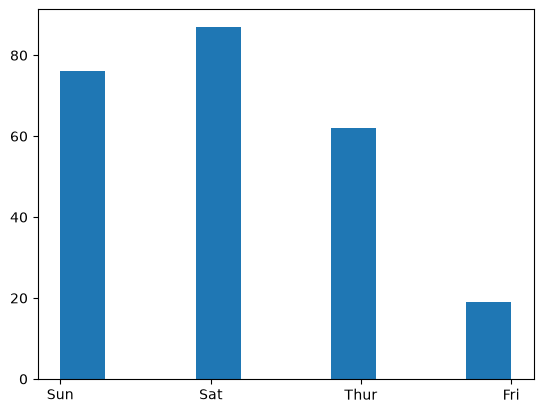

In [14]:
plt.hist(tips["day"])
plt.show()

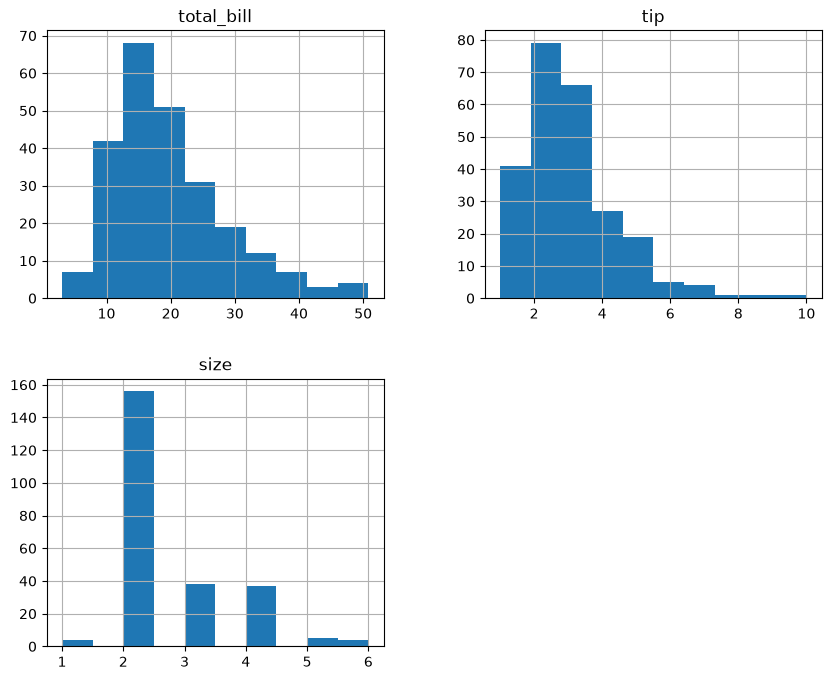

In [15]:
# Histogram plot
tips.hist(figsize=(10, 8))
plt.show()

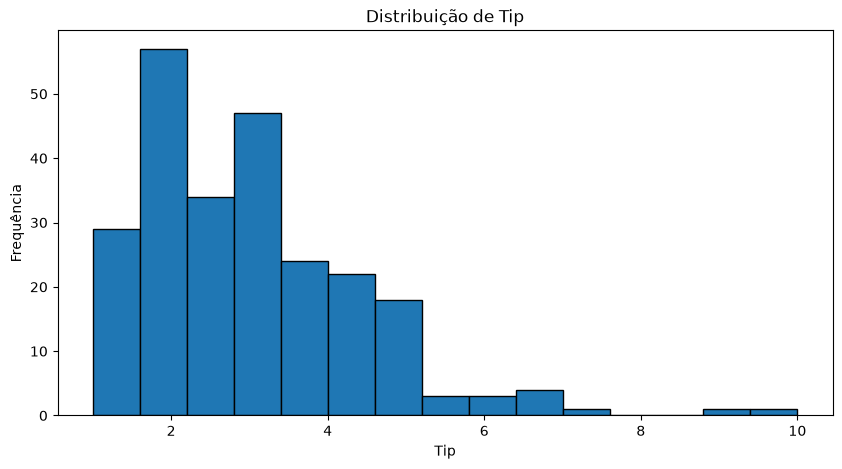

In [16]:
plt.figure(figsize=(10, 5))
plt.hist(tips['tip'], bins=15, edgecolor='black')
plt.xlabel('Tip')
plt.ylabel('Frequência')
plt.title('Distribuição de Tip')
plt.show()

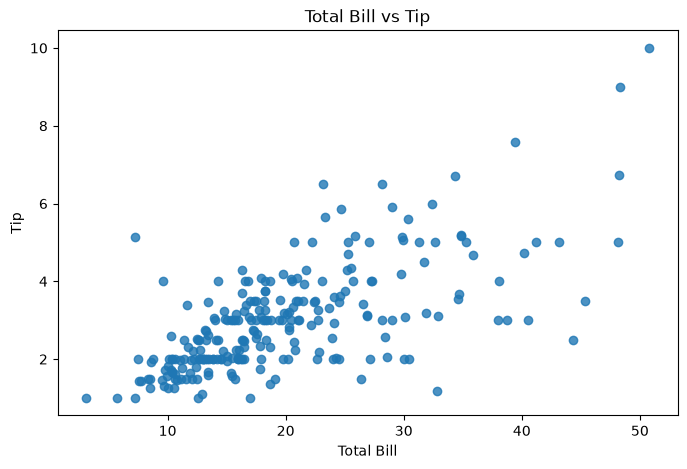

In [17]:
# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(tips['total_bill'], tips['tip'], alpha=0.8)
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.title('Total Bill vs Tip')
plt.show()

## Part 2 - Preprocessing

In this part we need to get the data ready for machine learning models. Since there are no missing values, we are left with converting the categorical data to numerical data. After this, we need to split the data into training sets and testing sets.
 - Convert the categorical columns (smoker, sex, day, time) into numercal columns with the `.replace()` method. For the `day` column, you can split it into the weekend days, and the non-weekend days. (Hint: Remember to drop the old columns before proceeding)
 - Check out the correlation between the columns. Delete the column with the smallest correlation with `tip`.
 - Separate the dataset into a target column (`tip`) and feature columns, and then split them into training and testing sets.

In [18]:
# Converting the categories into numerical values
tips['sex_num'] = tips['sex'].map({'Male': 0, 'Female': 1})
tips['smoker_num'] = tips['smoker'].map({'No': 0, 'Yes': 1})
tips['time_num'] = tips['time'].map({'Lunch': 0, 'Dinner': 1})

tips['weekend'] = tips['day'].map({
    'Thur': 0, 'Fri': 0, 'Sat': 1, 'Sun': 1
})

In [19]:
# Drop the old categorical columns
tips.drop(columns=["sex","smoker","time","day"],inplace=True)

In [20]:
# Check out the corrlation of the columns
tips.corr()

,total_bill,tip,size,sex_num,smoker_num,time_num,weekend
total_bill,1.000000,0.675734,0.598315,-0.144877,0.085721,0.183118,0.176770
tip,0.675734,1.000000,0.489299,-0.088862,0.005929,0.121629,0.120198
size,0.598315,0.489299,1.000000,-0.086195,-0.133178,0.103411,0.148022
sex_num,-0.144877,-0.088862,-0.086195,1.000000,-0.002816,-0.205231,-0.220194
smoker_num,0.085721,0.005929,-0.133178,-0.002816,1.000000,0.054921,-0.020196
time_num,0.183118,0.121629,0.103411,-0.205231,0.054921,1.000000,0.881758
weekend,0.176770,0.120198,0.148022,-0.220194,-0.020196,0.881758,1.000000


In [21]:
# Remove the smoker column
tips.drop(columns=["smoker_num"],inplace= True)

In [22]:
# Separate the features and the target (tip)
X=tips.drop(columns=["tip"])
y=tips["tip"]

In [23]:
# Import the train_test_split function
from sklearn.model_selection import train_test_split    

In [24]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


## Part 3 - Machine Learning

Now we are at the last step. Train a regression machine learning model and check how well it does on the data. What is the error you get?

- (Pro) Put you machine learning model into a pipeline where you also scale the data.
- (Mega Pro) Compare two different machine learning models to see which one peforms the best.

In [25]:
# Relevant imports
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [26]:
# Create linear regression model (or pipeline)
pipe = Pipeline([('scaler', StandardScaler()),
                 ('model', LinearRegression())])

In [27]:
# Fitting the model (or pipeline)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['total_bill','size','sex_num','time_num','weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [38]:
# Find the absolute error of the linear regression model
y_pred = pipe.predict(X_test)
from sklearn.metrics import mean_absolute_error
mae= mean_absolute_error(y_test, y_pred)
print(mae)

0.6663762301299571


In [36]:
# Create polynomial regression model (or pipeline)
from sklearn.preprocessing import PolynomialFeatures

poly_pipe = Pipeline([
    ('poly', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])


In [37]:
# Fitting the model (or pipeline)
poly_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('poly', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['total_bill','size','sex_num','time_num','weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",True
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


In [40]:
# Finding the absolute error of the polynomial regression model 
y_polypred= poly_pipe.predict(X_test)
mae2 = mean_absolute_error(y_test, y_polypred)
print(mae2)

0.8372938075652498
